# Avaliação de previsão com Group Time Series Split (janela expansiva) e dados jitterados

Este notebook compara quatro cenários de avaliação:

1. **baseline** — reproduz a abordagem original dos notebooks `Previsao_area1.ipynb` / `Previsao_area2.ipynb` na íntegra: split aleatório 70/30 treino/calibração (não respeita a ordem temporal) **com o ensemble original** (GradientBoosting + RandomForest, pesos 3:1). Os outros três cenários usam **Extra Trees**.
2. **expanding** — Group Time Series Split expansivo por `Ano`, com 2 folds. Cada fold treina em ano(s) passado(s) e testa no ano seguinte, nunca visto durante o treino.
3. **expanding_jitter** — igual ao `expanding`, mas o (sub)treino e a calibração de cada fold são aumentados com 5 clones jitterados (ruído gaussiano de 0.35 nas colunas climáticas contínuas). O conjunto de teste **nunca** é jitterado, pois precisa representar dados reais.
4. **expanding_semestral** — o mesmo Group Time Series Split expansivo, mas agrupando por **semestre** em vez de ano (2023-S1, 2023-S2, ..., 2025-S1, 2025-S2 = 6 grupos), com **5 folds** expansivos.

Cada cenário é repetido `N_RUNS = 15` vezes (variando a semente aleatória) para termos uma distribuição das métricas, não só um número. As métricas comparadas são **MAE**, **RMSE**, a **margem** de conformal prediction (95%) e a **cobertura empírica** (fração de casos em que o erro real ficou dentro da margem).

**Área a testar:** agora é escolhida por uma única variável `AREA` na célula de configuração — `'area1'`, `'area2'` ou `'ambas'`.

**Atenção:** com essa mudança, o `baseline` passa a diferir dos demais cenários em duas coisas ao mesmo tempo (split *e* modelo), não só no split. Isso é intencional — serve de referência "como era antes" — mas significa que, se o `baseline` sair melhor ou pior que o `expanding`, não dá pra saber sozinho se foi o split ou o modelo que causou a diferença (mais detalhes nas notas finais).

**Este notebook não foi executado.** Rode você mesmo — dependendo de `AREA` e do hardware, pode ajustar bastante ExtraTreesRegressor (4 cenários × 15 execuções × folds), então pode demorar alguns minutos. Reduza `N_RUNS` ou `N_ESTIMATORS` na célula de configuração se quiser um teste mais rápido.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor, VotingRegressor,
)

np.random.seed(42)

## Configuração

In [14]:
# Escolha a área a processar: 'area1', 'area2' ou 'ambas' (roda as duas e compara).
AREA = 'area1'  # 'area1', 'area2' ou 'ambas'

if AREA == 'ambas':
    AREAS = ['area1', 'area2']
elif AREA in ('area1', 'area2'):
    AREAS = [AREA]
else:
    raise ValueError("AREA deve ser 'area1', 'area2' ou 'ambas'")

CONFIG = {
    'area1': {
        'csv_path': 'dataatea1clima.csv',
        'onehot_cols': ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                        'prato_principal_2', 'guarnição', 'sobremesa_1', 'refeicao'],
        'remove_cafe_da_manha': True,
        'dropna': True,
        'remove_total_zero': True,
    },
    'area2': {
        'csv_path': 'dataarea2clima.csv',
        'onehot_cols': ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                        'prato_principal_2', 'guarnição', 'sobremesa_1'],
        'remove_cafe_da_manha': False,
        'dropna': False,
        'remove_total_zero': False,
    },
}

Y_COL = 'total'
GROUP_COL = 'Ano'  # usado para o split temporal anual (Group Time Series Split)

# Colunas climáticas contínuas usadas no jitter (ruído gaussiano)
COLS_CLIMATICAS = [
    'Precipitacao_mm', 'Temp_max_C', 'Temp_min_C',
    'Umid_rel_ar', 'Vento_velocidade_ms', 'Vento_rajada_maxima_ms',
]

# --- Parâmetros dos experimentos ---
N_RUNS = 15              # repetições por cenário (para medir variância das métricas)
N_SPLITS = 2             # nº de folds do Group Time Series Split expansivo (por Ano)
N_SPLITS_SEMESTRE = 5    # nº de folds do Group Time Series Split expansivo (por Semestre)
N_CLONES = 5             # nº de clones jitterados gerados por observação
NOISE_LEVEL = 0.35       # intensidade do ruído (proporção do desvio-padrão da coluna)
N_ESTIMATORS = 200       # nº de árvores do ExtraTreesRegressor
ALPHA = 0.05             # nível de significância -> 95% de confiança (conformal prediction)
CALIB_SIZE = 0.3         # proporção usada para calibração dentro de cada bloco de treino

## Carregamento e preparação dos dados

Replica as mesmas regras de limpeza usadas em `Previsao_area1.ipynb` / `Previsao_area2.ipynb`. As colunas `Ano` e `Semestre` ficam de fora do one-hot: `Ano` continua como atributo numérico do modelo (igual à metodologia original) e, junto com `Semestre` (derivado de `Ano` e `Mês`), é guardado separadamente para servir de grupo temporal nos splits expansivos.

In [15]:
def carregar_e_preparar(area):
    '''
    Carrega e limpa os dados de uma área, replicando as mesmas regras usadas
    em Previsao_area1.ipynb / Previsao_area2.ipynb (filtragem de café da manhã,
    dropna, remoção de total==0, descarte de categorias raras) e aplica o
    one-hot encoding.

    Retorna X (DataFrame), y (Series), grupos_ano (Series com o Ano de cada
    linha) e grupos_semestre (Series com Ano*10 + semestre, ex.: 20231 para
    o 1º semestre de 2023), ambos calculados ANTES do one-hot, usados como
    grupo temporal nos splits expansivos.
    '''
    cfg = CONFIG[area]
    data = pd.read_csv(cfg['csv_path'], header=0)
    colunas_clima_faltantes = [col for col in COLS_CLIMATICAS if col not in data.columns]
    if colunas_clima_faltantes:
        raise ValueError(
            f"O CSV de {area} não contém as colunas climáticas esperadas: "
            f"{colunas_clima_faltantes}. Verifique se o caminho aponta para o arquivo com clima."
        )

    if cfg['remove_cafe_da_manha']:
        data = data[data['refeicao'] != 'cafe da manha'].copy()

    if cfg['dropna']:
        data = data.dropna()

    if cfg['remove_total_zero']:
        data = data[data[Y_COL] != 0]

    # Descarta categorias que aparecem menos de 5 vezes (igual aos notebooks originais)
    for col in ['guarnição', 'prato_principal_1', 'prato_principal_2', 'sobremesa_1']:
        data = data.groupby(col).filter(lambda x: len(x) >= 5)

    data = data.reset_index(drop=True)

    # Ano e Semestre ficam de fora do one-hot -> usados como grupo temporal.
    # Ano também continua como atributo numérico do modelo (igual à metodologia original).
    grupos_ano = data[GROUP_COL].copy()
    grupos_semestre = grupos_ano * 10 + np.where(data['Mês'] <= 6, 1, 2)
    grupos_semestre = grupos_semestre.rename('Semestre')

    data_onehot = pd.get_dummies(data, columns=cfg['onehot_cols'])

    atributos = data_onehot.drop(columns=[Y_COL]).columns
    X = data_onehot[atributos]
    y = data_onehot[Y_COL]

    return X, y, grupos_ano, grupos_semestre

## Funções auxiliares: split temporal, jitter e métricas

In [16]:
def expanding_group_splits(groups, n_splits, min_train_groups=1):
    '''
    Group Time Series Split expansivo (genérico, funciona para qualquer
    agrupamento: por Ano, por Semestre, etc.).

    Ordena os grupos únicos e usa os últimos `n_splits` grupos como teste,
    um por vez, com o treino sempre expandindo para incluir todos os grupos
    anteriores.

    Ex.: 3 anos e n_splits=2 gera:
      fold 0: treino=[2023]        teste=[2024]
      fold 1: treino=[2023, 2024]  teste=[2025]

    Ex.: 6 semestres e n_splits=5 tentaria gerar 5 folds, mas o primeiro
    treinaria com apenas 1 semestre. Com `min_train_groups=2`, esse fold é
    pulado e sobram 4 folds, todos com pelo menos 2 semestres de treino.

    `min_train_groups`: nº mínimo de grupos no treino para o fold ser gerado;
    folds cujo treino ficaria menor que isso são simplesmente ignorados.

    Retorna (train_idx, test_idx, train_groups, test_group) para cada fold.
    '''
    groups = np.asarray(groups)
    unique_groups = np.sort(np.unique(groups))
    n_groups = len(unique_groups)

    if n_splits >= n_groups:
        raise ValueError(
            f'n_splits ({n_splits}) deve ser menor que o número de grupos únicos ({n_groups}).'
        )

    start = n_groups - n_splits
    for i in range(n_splits):
        train_groups = unique_groups[: start + i]
        if len(train_groups) < min_train_groups:
            continue
        test_group = unique_groups[start + i]
        train_idx = np.where(np.isin(groups, train_groups))[0]
        test_idx = np.where(groups == test_group)[0]
        yield train_idx, test_idx, train_groups, test_group

In [17]:
def gerar_clones_jitter(X_part, y_part, cols_climaticas, n_clones=5, noise_level=0.35, rng=None):
    '''
    Gera `n_clones` cópias jitteradas de X_part/y_part, adicionando ruído
    gaussiano às colunas climáticas contínuas (desvio = noise_level * desvio-
    padrão da coluna). As demais colunas (calendário, cardápio, Ano) e o
    alvo `y` permanecem inalterados em cada clone.

    Retorna X e y "aumentados": dados originais + os `n_clones` clones.
    '''
    if rng is None:
        rng = np.random.default_rng()

    X_aug_list = [X_part.copy()]
    y_aug_list = [y_part.copy()]

    stds = X_part[cols_climaticas].std(ddof=0)

    for _ in range(n_clones):
        X_clone = X_part.copy()
        for col in cols_climaticas:
            ruido = rng.normal(loc=0.0, scale=noise_level * stds[col], size=len(X_clone))
            X_clone[col] = X_clone[col] + ruido

        # Evita valores fisicamente inválidos criados pelo ruído
        if 'Precipitacao_mm' in X_clone.columns:
            X_clone['Precipitacao_mm'] = X_clone['Precipitacao_mm'].clip(lower=0)
        if 'Umid_rel_ar' in X_clone.columns:
            X_clone['Umid_rel_ar'] = X_clone['Umid_rel_ar'].clip(lower=0, upper=100)

        X_aug_list.append(X_clone)
        y_aug_list.append(y_part.copy())

    X_aug = pd.concat(X_aug_list, ignore_index=True)
    y_aug = pd.concat(y_aug_list, ignore_index=True)
    return X_aug, y_aug

In [18]:
def calcular_metricas(y_true, y_pred, margem):
    '''
    MAE, RMSE, a própria margem de conformal prediction e a cobertura
    empírica (fração de observações cujo |erro| ficou dentro da margem).
    '''
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    residuos = y_true - y_pred
    abs_res = np.abs(residuos)

    return {
        'MAE': abs_res.mean(),
        'RMSE': np.sqrt((residuos ** 2).mean()),
        'margem': margem,
        'cobertura': (abs_res <= margem).mean(),
    }

## Cenários de avaliação

- **baseline**: reproduz a abordagem original por completo (split aleatório 70/30 **e** o ensemble GB+RF, pesos 3:1).
- **expanding**: Group Time Series Split expansivo por `Ano` (2 folds) — o teste é sempre o ano seguinte, nunca visto no treino/calibração.
- **expanding_jitter**: igual ao `expanding`, mas o subtreino e a calibração de cada fold são aumentados com clones jitterados. O teste nunca é jitterado.
- **expanding_semestral**: igual ao `expanding`, mas agrupando por semestre (5 folds em vez de 2) — mais folds, mas os primeiros treinam com bem menos dados (o fold 0 treina em apenas 1 semestre).

In [19]:
def rodar_baseline(X, y, n_runs=N_RUNS, test_size=CALIB_SIZE, n_estimators=N_ESTIMATORS, alpha=ALPHA):
    '''
    Cenário 'baseline': reproduz a abordagem ORIGINAL dos notebooks de previsão
    (Previsao_area1.ipynb / Previsao_area2.ipynb) na íntegra — split aleatório
    treino/calibração (sem respeitar a ordem temporal) E o mesmo ensemble
    votante usado ali (GradientBoostingRegressor + RandomForestRegressor,
    pesos 3:1).

    Atenção: diferente dos outros três cenários (que usam Extra Trees), este
    usa deliberadamente o modelo original. Isso significa que a diferença
    baseline vs expanding* não isola só o efeito do split — também muda o
    algoritmo. Serve como ponto de referência "como era antes", não como
    comparação 1:1 de algoritmo (para isso, seria preciso um baseline com
    Extra Trees também — dá pra adicionar depois se quiser separar os dois
    efeitos).
    '''
    nivel_confianca = 1 - alpha
    resultados = []

    for run in range(n_runs):
        seed = run
        X_train, X_calib, y_train, y_calib = train_test_split(
            X, y, test_size=test_size, random_state=seed
        )

        modelo = VotingRegressor(
            estimators=[
                ('gb', GradientBoostingRegressor(n_estimators=n_estimators, random_state=seed)),
                ('rf', RandomForestRegressor(n_estimators=n_estimators, random_state=seed)),
            ],
            weights=[3, 1],
        )
        modelo.fit(X_train, y_train)

        y_calib_pred = modelo.predict(X_calib)
        residuos_calib = np.abs(y_calib.to_numpy() - y_calib_pred)
        margem = np.quantile(residuos_calib, nivel_confianca, method='higher')

        metricas = calcular_metricas(y_calib, y_calib_pred, margem)
        metricas.update({'run': run, 'cenario': 'baseline', 'fold': None, 'ano_teste': None})
        resultados.append(metricas)

    return pd.DataFrame(resultados)

In [20]:
def rodar_expanding(X, y, grupos_ano, n_splits=N_SPLITS, n_runs=N_RUNS,
                     calib_size=CALIB_SIZE, n_estimators=N_ESTIMATORS, alpha=ALPHA):
    '''
    Cenário 'expanding': Group Time Series Split expansivo por Ano.
    Em cada fold, o modelo é calibrado com uma fatia do próprio bloco de
    treino e depois avaliado no ano seguinte (nunca visto durante o ajuste).
    '''
    nivel_confianca = 1 - alpha
    resultados = []

    for run in range(n_runs):
        seed = run
        splits = expanding_group_splits(grupos_ano.to_numpy(), n_splits)

        for fold_i, (train_idx, test_idx, train_groups, test_group) in enumerate(splits):
            X_train_fold, y_train_fold = X.iloc[train_idx], y.iloc[train_idx]
            X_test_fold, y_test_fold = X.iloc[test_idx], y.iloc[test_idx]

            X_sub, X_calib, y_sub, y_calib = train_test_split(
                X_train_fold, y_train_fold, test_size=calib_size, random_state=seed
            )

            modelo_calib = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_calib.fit(X_sub, y_sub)

            y_calib_pred = modelo_calib.predict(X_calib)
            residuos_calib = np.abs(y_calib.to_numpy() - y_calib_pred)
            margem = np.quantile(residuos_calib, nivel_confianca, method='higher')

            # Modelo final: reajustado com todo o bloco de treino (sub + calibração),
            # igual à metodologia dos notebooks originais, e avaliado no ano futuro.
            modelo_final = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_final.fit(X_train_fold, y_train_fold)
            y_test_pred = modelo_final.predict(X_test_fold)

            metricas = calcular_metricas(y_test_fold, y_test_pred, margem)
            metricas.update({
                'run': run, 'cenario': 'expanding',
                'fold': fold_i, 'ano_teste': int(test_group),
            })
            resultados.append(metricas)

    return pd.DataFrame(resultados)

In [21]:
def rodar_expanding_jitter(X, y, grupos_ano, cols_climaticas, n_splits=N_SPLITS, n_runs=N_RUNS,
                            calib_size=CALIB_SIZE, n_clones=N_CLONES, noise_level=NOISE_LEVEL,
                            n_estimators=N_ESTIMATORS, alpha=ALPHA):
    '''
    Cenário 'expanding_jitter': igual ao 'expanding', mas o subtreino e a
    calibração de cada fold são aumentados com `n_clones` clones jitterados
    (ruído gaussiano com desvio `noise_level` * desvio-padrão em cada coluna
    climática). O conjunto de teste (ano futuro) nunca é jitterado.
    '''
    nivel_confianca = 1 - alpha
    resultados = []

    for run in range(n_runs):
        seed = run
        rng = np.random.default_rng(seed)
        splits = expanding_group_splits(grupos_ano.to_numpy(), n_splits)

        for fold_i, (train_idx, test_idx, train_groups, test_group) in enumerate(splits):
            X_train_fold = X.iloc[train_idx].reset_index(drop=True)
            y_train_fold = y.iloc[train_idx].reset_index(drop=True)
            X_test_fold, y_test_fold = X.iloc[test_idx], y.iloc[test_idx]

            X_sub, X_calib, y_sub, y_calib = train_test_split(
                X_train_fold, y_train_fold, test_size=calib_size, random_state=seed
            )

            # Jitter aplicado separadamente ao subtreino e à calibração, para
            # que clones de uma mesma observação não "vazem" entre os dois.
            X_sub_aug, y_sub_aug = gerar_clones_jitter(
                X_sub, y_sub, cols_climaticas, n_clones, noise_level, rng
            )
            X_calib_aug, y_calib_aug = gerar_clones_jitter(
                X_calib, y_calib, cols_climaticas, n_clones, noise_level, rng
            )

            modelo_calib = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_calib.fit(X_sub_aug, y_sub_aug)

            y_calib_pred = modelo_calib.predict(X_calib_aug)
            residuos_calib = np.abs(y_calib_aug.to_numpy() - y_calib_pred)
            margem = np.quantile(residuos_calib, nivel_confianca, method='higher')

            # Modelo final: reajustado com o bloco de treino inteiro (também jitterado)
            X_train_fold_aug, y_train_fold_aug = gerar_clones_jitter(
                X_train_fold, y_train_fold, cols_climaticas, n_clones, noise_level, rng
            )
            modelo_final = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_final.fit(X_train_fold_aug, y_train_fold_aug)
            y_test_pred = modelo_final.predict(X_test_fold)  # teste sempre com dados reais

            metricas = calcular_metricas(y_test_fold, y_test_pred, margem)
            metricas.update({
                'run': run, 'cenario': 'expanding_jitter',
                'fold': fold_i, 'ano_teste': int(test_group),
            })
            resultados.append(metricas)

    return pd.DataFrame(resultados)

In [22]:
def rodar_expanding_semestral(X, y, grupos_semestre, n_splits=N_SPLITS_SEMESTRE, n_runs=N_RUNS,
                               calib_size=CALIB_SIZE, n_estimators=N_ESTIMATORS, alpha=ALPHA,
                               min_train_semestres=2):
    '''
    Cenário 'expanding_semestral': igual ao 'expanding', mas o agrupamento
    temporal é por semestre (2023-S1, 2023-S2, ..., 2025-S1, 2025-S2 = 6
    grupos) em vez de por ano.

    Com N_SPLITS_SEMESTRE=5 e 6 semestres únicos, o primeiro fold treinaria
    com apenas 1 semestre de dados — treino pequeno demais, que estava
    distorcendo as métricas do cenário inteiro. Por isso esse fold é pulado
    via `min_train_semestres=2`: sobram 4 folds, todos com pelo menos 2
    semestres de treino.
    '''
    nivel_confianca = 1 - alpha
    resultados = []

    for run in range(n_runs):
        seed = run
        splits = expanding_group_splits(grupos_semestre.to_numpy(), n_splits, min_train_groups=min_train_semestres)

        for fold_i, (train_idx, test_idx, train_groups, test_group) in enumerate(splits):
            X_train_fold, y_train_fold = X.iloc[train_idx], y.iloc[train_idx]
            X_test_fold, y_test_fold = X.iloc[test_idx], y.iloc[test_idx]

            X_sub, X_calib, y_sub, y_calib = train_test_split(
                X_train_fold, y_train_fold, test_size=calib_size, random_state=seed
            )

            modelo_calib = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_calib.fit(X_sub, y_sub)

            y_calib_pred = modelo_calib.predict(X_calib)
            residuos_calib = np.abs(y_calib.to_numpy() - y_calib_pred)
            margem = np.quantile(residuos_calib, nivel_confianca, method='higher')

            modelo_final = ExtraTreesRegressor(n_estimators=n_estimators, random_state=seed, n_jobs=-1)
            modelo_final.fit(X_train_fold, y_train_fold)
            y_test_pred = modelo_final.predict(X_test_fold)

            metricas = calcular_metricas(y_test_fold, y_test_pred, margem)
            ano_teste = int(test_group) // 10
            semestre_teste = int(test_group) % 10
            metricas.update({
                'run': run, 'cenario': 'expanding_semestral',
                'fold': fold_i, 'ano_teste': ano_teste, 'semestre_teste': semestre_teste,
            })
            resultados.append(metricas)

    return pd.DataFrame(resultados)

## Execução (área(s) escolhida(s) em `AREA`, todos os cenários)

**Não rodei esta célula.** Rode você mesmo — pode demorar alguns minutos, dependendo do hardware e de `AREA`.

In [23]:
resultados_por_area = []

for area in AREAS:
    print(f'=== Processando {area} ===')
    X, y, grupos_ano, grupos_semestre = carregar_e_preparar(area)
    print(f'  {len(X)} observações, {X.shape[1]} atributos, anos: {sorted(grupos_ano.unique())}')

    print('  Rodando baseline...')
    df_baseline = rodar_baseline(X, y)

    print('  Rodando expanding (anual, 2 folds)...')
    df_expanding = rodar_expanding(X, y, grupos_ano)

    print('  Rodando expanding + jitter (anual, 2 folds)...')
    df_expanding_jitter = rodar_expanding_jitter(X, y, grupos_ano, COLS_CLIMATICAS)

    print('  Rodando expanding semestral (4 folds válidos, pulando o de treino c/ 1 semestre)...')
    df_expanding_semestral = rodar_expanding_semestral(X, y, grupos_semestre)

    for df in (df_baseline, df_expanding, df_expanding_jitter, df_expanding_semestral):
        df['area'] = area

    resultados_por_area.extend([df_baseline, df_expanding, df_expanding_jitter, df_expanding_semestral])

resultados_df = pd.concat(resultados_por_area, ignore_index=True)
resultados_df.head()

=== Processando area1 ===
  1363 observações, 200 atributos, anos: [np.int64(2023), np.int64(2024), np.int64(2025)]
  Rodando baseline...
  Rodando expanding (anual, 2 folds)...
  Rodando expanding + jitter (anual, 2 folds)...
  Rodando expanding semestral (4 folds válidos, pulando o de treino c/ 1 semestre)...


,MAE,RMSE,margem,cobertura,run,cenario,fold,ano_teste,area,semestre_teste
0,128.417613,171.139768,346.142899,0.9511,0,baseline,None,None,area1,NaN
1,122.893371,159.522298,309.646189,0.9511,1,baseline,None,None,area1,NaN
2,131.511449,171.840127,344.772843,0.9511,2,baseline,None,None,area1,NaN
3,127.205995,170.667146,342.102713,0.9511,3,baseline,None,None,area1,NaN
4,129.047433,173.311912,343.493907,0.9511,4,baseline,None,None,area1,NaN


## Tabela resumo (média ± desvio-padrão das 15 execuções, por cenário e área)

In [24]:
tabela_resumo = (
    resultados_df
    .groupby(['area', 'cenario'])[['MAE', 'RMSE', 'margem', 'cobertura']]
    .agg(['mean', 'std'])
)
tabela_resumo.columns = ['_'.join(col) for col in tabela_resumo.columns]
tabela_resumo = tabela_resumo.reset_index().round(2)
tabela_resumo

,area,cenario,MAE_mean,MAE_std,RMSE_mean,RMSE_std,margem_mean,margem_std,cobertura_mean,cobertura_std
0,area1,baseline,126.59,5.55,167.44,8.25,340.98,20.01,0.95,0.00
1,area1,expanding,165.92,10.30,212.59,8.92,490.48,74.86,0.97,0.02
2,area1,expanding_jitter,163.41,10.53,210.89,8.53,492.45,82.96,0.97,0.02
3,area1,expanding_semestral,178.07,16.08,224.58,20.15,474.22,60.52,0.96,0.03


In [25]:
# Quanto cada cenário melhora (ou piora) o MAE em relação ao baseline e ao expanding "puro" (anual).
pivot_mae = tabela_resumo.pivot(index='area', columns='cenario', values='MAE_mean')
comparacoes = pd.DataFrame(index=pivot_mae.index)

if {'baseline', 'expanding'}.issubset(pivot_mae.columns):
    comparacoes['expanding_vs_baseline (%)'] = 100 * (
        pivot_mae['expanding'] - pivot_mae['baseline']
    ) / pivot_mae['baseline']

if {'expanding', 'expanding_jitter'}.issubset(pivot_mae.columns):
    comparacoes['expanding_jitter_vs_expanding (%)'] = 100 * (
        pivot_mae['expanding_jitter'] - pivot_mae['expanding']
    ) / pivot_mae['expanding']

if {'expanding', 'expanding_semestral'}.issubset(pivot_mae.columns):
    comparacoes['expanding_semestral_vs_expanding (%)'] = 100 * (
        pivot_mae['expanding_semestral'] - pivot_mae['expanding']
    ) / pivot_mae['expanding']

pd.concat([pivot_mae, comparacoes], axis=1).round(2)

,baseline,expanding,expanding_jitter,expanding_semestral,expanding_vs_baseline (%),expanding_jitter_vs_expanding (%),expanding_semestral_vs_expanding (%)
area,,,,,,,
area1,126.59,165.92,163.41,178.07,31.07,-1.51,7.32


## Gráficos comparativos

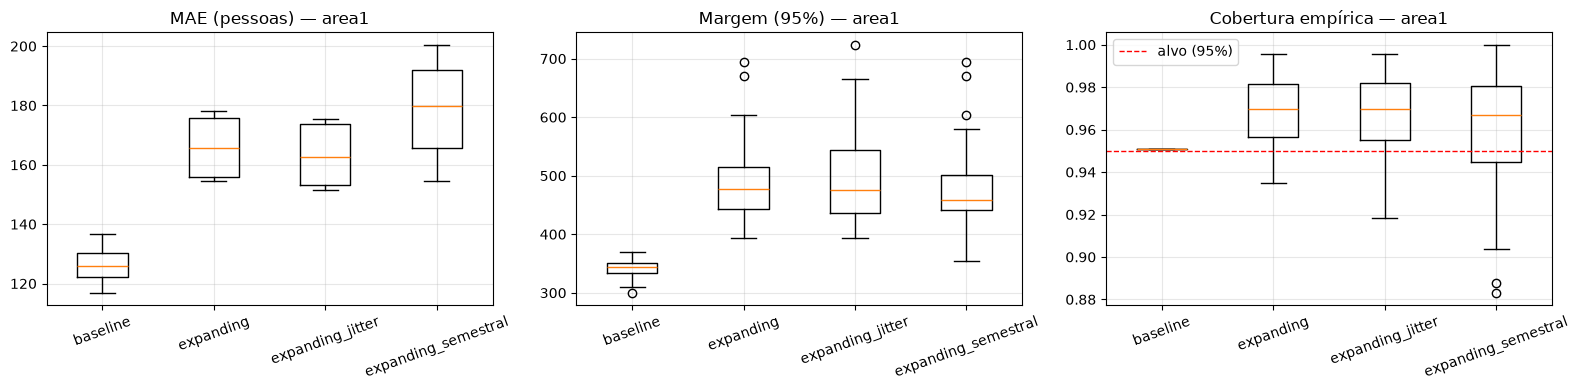

In [27]:
ordem_cenarios = ['baseline', 'expanding', 'expanding_jitter', 'expanding_semestral']

for area in AREAS:
    subset = resultados_df[resultados_df['area'] == area]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    metricas_plot = ['MAE', 'margem', 'cobertura']
    titulos = ['MAE (pessoas)', 'Margem (95%)', 'Cobertura empírica']

    for ax, metrica, titulo in zip(axes, metricas_plot, titulos):
        dados = [subset[subset['cenario'] == c][metrica].dropna().values for c in ordem_cenarios]
        ax.boxplot(dados, tick_labels=ordem_cenarios)
        ax.set_title(f'{titulo} — {area}')
        ax.tick_params(axis='x', rotation=20)
        ax.grid(True, alpha=0.3)
        if metrica == 'cobertura':
            ax.axhline(1 - ALPHA, color='red', linestyle='--', linewidth=1, label=f'alvo ({1 - ALPHA:.0%})')
            ax.legend()

    plt.tight_layout()
    plt.show()

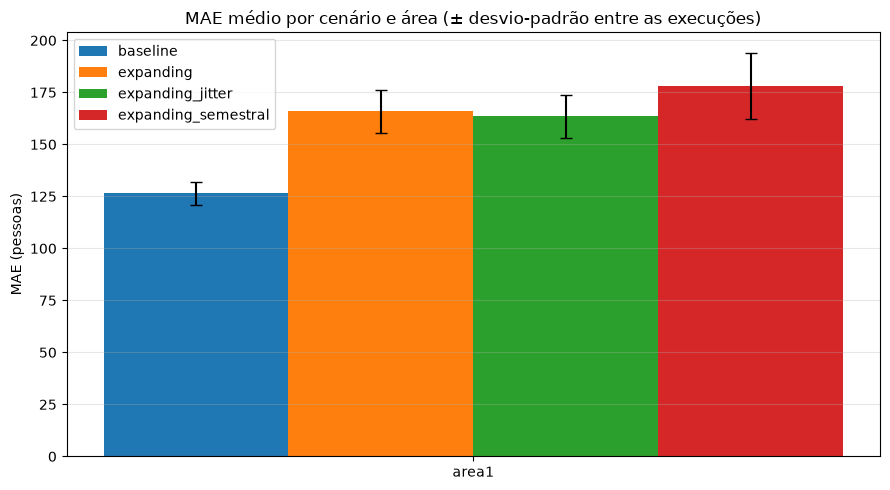

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
largura = 0.2
x = np.arange(len(AREAS))

for i, cenario in enumerate(ordem_cenarios):
    medias = [
        tabela_resumo.loc[(tabela_resumo['area'] == area) & (tabela_resumo['cenario'] == cenario), 'MAE_mean'].values[0]
        for area in AREAS
    ]
    desvios = [
        tabela_resumo.loc[(tabela_resumo['area'] == area) & (tabela_resumo['cenario'] == cenario), 'MAE_std'].values[0]
        for area in AREAS
    ]
    ax.bar(x + (i - 1.5) * largura, medias, width=largura, yerr=desvios, capsize=4, label=cenario)

ax.set_xticks(x)
ax.set_xticklabels(AREAS)
ax.set_ylabel('MAE (pessoas)')
ax.set_title('MAE médio por cenário e área (± desvio-padrão entre as execuções)')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [29]:
# Opcional: salva os resultados brutos para análises futuras.
resultados_df.to_csv('resultados_comparacao_cv.csv', index=False)